# SAT (Glucose3)
Notebook chạy lại ví dụ nhỏ, đọc số liệu đo thật (`sat.csv`) và vẽ biểu đồ bằng `analysis.py`. Không chạy lại toàn bộ 45 lượt đo; để đo lại dùng `python -m task1_nqueens.sat_experiment`.

In [ ]:
from pathlib import Path
import sys
# Tìm thư mục chứa package task1_nqueens, chạy được từ bất kỳ thư mục con nào.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "task1_nqueens" / "data" / "measured").exists())
sys.path.insert(0, str(ROOT))
MEASURED = ROOT / "task1_nqueens" / "data" / "measured"
print("Root:", ROOT.name)

Root: build


In [ ]:
import csv
from task1_nqueens.sat_solver import SATSolver
for n in (4, 5, 8):
    result = SATSolver().solve(n)
    assert result["sat"]
    print(n, result["num_clauses"], result["solution"])

4 80 [2, 0, 3, 1]
5 165 [3, 1, 4, 2, 0]
8 736 [2, 5, 3, 1, 7, 4, 6, 0]


In [ ]:
with (MEASURED / "sat.csv").open() as f:
    rows = list(csv.DictReader(f))
print("Measured trials:", len(rows))
assert len(rows) == 45 and all(r["sat"] == "True" for r in rows)
with (MEASURED / "sat_summary.csv").open() as f:
    print(f.read())

Measured trials: 45
N,num_clauses,mean_s,stdev_s
4,80,1.042000003508292e-05,7.09626657666746e-06
5,165,4.239999907440506e-06,3.0495903933852837e-07
8,736,3.7720000182162036e-05,1.3236317177731995e-06
12,2608,7.513999989896547e-05,8.354642192711861e-07
16,6336,0.0010881199999857928,1.0143323065283888e-05
24,21920,0.0037474600001587534,7.159338619653294e-05
32,52608,0.013337560000218218,0.0004915651975316911
48,179776,0.2714869399998861,0.00229845220481945
64,428800,0.17416279999961262,0.006475621851603716



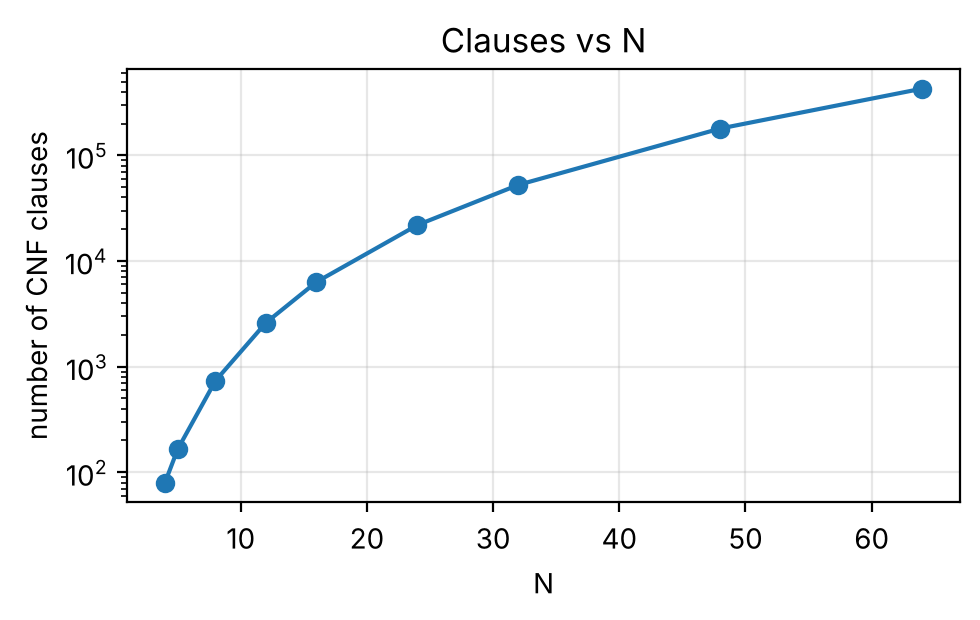

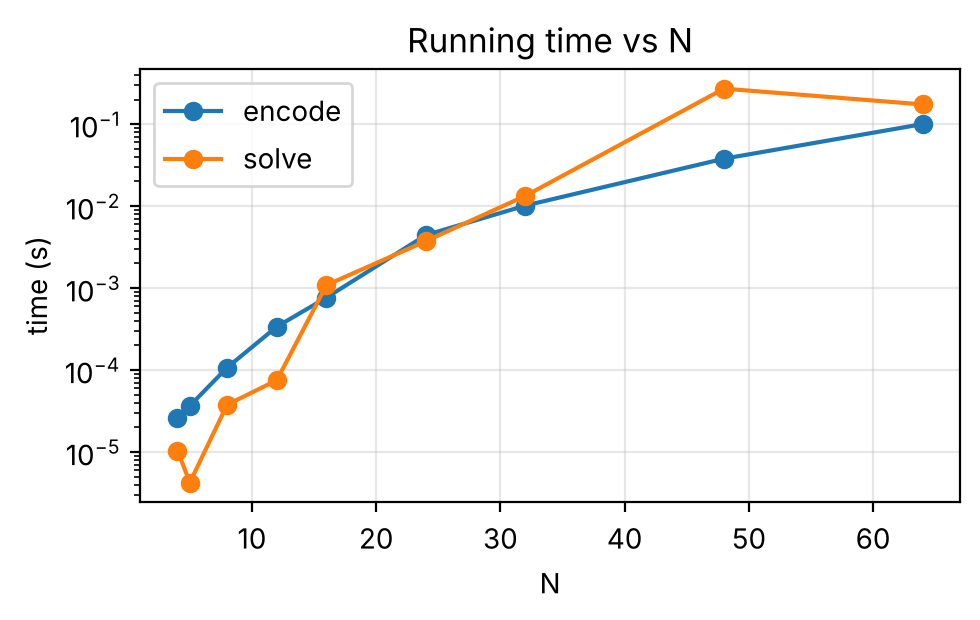

In [ ]:
from task1_nqueens.analysis import SATPlotter
from IPython.display import Image, display
SATPlotter(str(MEASURED / "sat.csv"), str(MEASURED / "figures")).plot()
for name in ("sat_clauses.png", "sat_time.png"):
    display(Image(filename=str(MEASURED / "figures" / name), width=480))